In [2]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score , confusion_matrix , classification_report
from sklearn.preprocessing import StandardScaler


In [4]:
data = load_breast_cancer()
x = data.data
y = data.target

In [8]:
x.shape , y.shape

((569, 30), (569,))

In [10]:
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size=0.2 , random_state = 42 , stratify =y)
x_train.shape , x_test.shape , y_train.shape , y_test.shape

((455, 30), (114, 30), (455,), (114,))

In [11]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [12]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled , y_train)

KNeighborsClassifier()

In [14]:
y_pred = knn.predict(x_test_scaled)
y_pred

array([0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1])

In [16]:
k_values = range(1,21)
accuracy_sc = []
for k in k_values:
  knn = KNeighborsClassifier(n_neighbors = k)
  knn.fit(x_train_scaled , y_train)
  y_pred = knn.predict(x_test_scaled)
  accuracy =accuracy_score(y_test , y_pred)
  accuracy_sc.append(accuracy)

In [17]:
accuracy_sc

[0.9385964912280702,
 0.9298245614035088,
 0.9824561403508771,
 0.9473684210526315,
 0.956140350877193,
 0.956140350877193,
 0.9736842105263158,
 0.9736842105263158,
 0.9736842105263158,
 0.9649122807017544,
 0.9736842105263158,
 0.9736842105263158,
 0.9736842105263158,
 0.9649122807017544,
 0.9736842105263158,
 0.9736842105263158,
 0.9824561403508771,
 0.9824561403508771,
 0.9736842105263158,
 0.9736842105263158]

In [18]:
for k , accuracy in zip(k_values , accuracy_sc):
  print(f"k = {k} , accuracy = {accuracy}")

k = 1 , accuracy = 0.9385964912280702
k = 2 , accuracy = 0.9298245614035088
k = 3 , accuracy = 0.9824561403508771
k = 4 , accuracy = 0.9473684210526315
k = 5 , accuracy = 0.956140350877193
k = 6 , accuracy = 0.956140350877193
k = 7 , accuracy = 0.9736842105263158
k = 8 , accuracy = 0.9736842105263158
k = 9 , accuracy = 0.9736842105263158
k = 10 , accuracy = 0.9649122807017544
k = 11 , accuracy = 0.9736842105263158
k = 12 , accuracy = 0.9736842105263158
k = 13 , accuracy = 0.9736842105263158
k = 14 , accuracy = 0.9649122807017544
k = 15 , accuracy = 0.9736842105263158
k = 16 , accuracy = 0.9736842105263158
k = 17 , accuracy = 0.9824561403508771
k = 18 , accuracy = 0.9824561403508771
k = 19 , accuracy = 0.9736842105263158
k = 20 , accuracy = 0.9736842105263158


In [19]:
best_k = k_values[np.argmax(accuracy_sc)]
best_k

3

In [20]:
best_ac = max(accuracy_sc)
best_ac

0.9824561403508771

Text(0, 0.5, 'Accuracy')

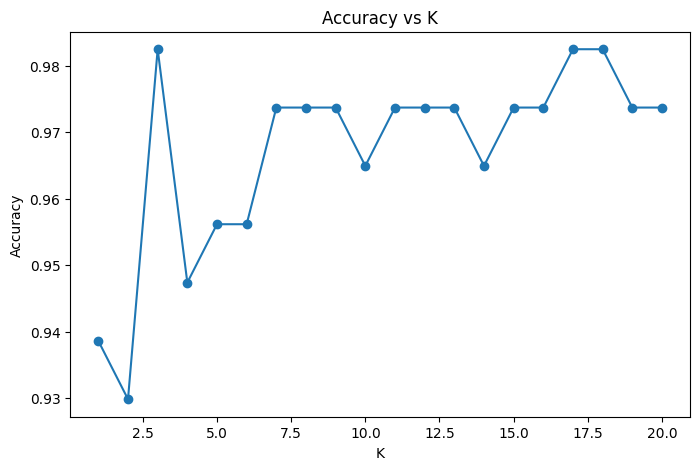

In [21]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(k_values , accuracy_sc , marker='o' , linestyle='-')
plt.title('Accuracy vs K')
plt.xlabel('K')
plt.ylabel('Accuracy')

In [22]:
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(x_train_scaled , y_train)


KNeighborsClassifier(n_neighbors=3)

In [24]:
best_pred = final_knn.predict(x_test_scaled)


In [26]:
acc = accuracy_score(y_test , best_pred)
cm = confusion_matrix(y_test , best_pred)
cr = classification_report(y_test , best_pred)

In [30]:
print('-----All metrics-----')
print(f'Accuracy : {acc}')
print(f'Confusion Matrix : \n{cm}')
print(f'Classification Report : \n{cr}')

-----All metrics-----
Accuracy : 0.9824561403508771
Confusion Matrix : 
[[40  2]
 [ 0 72]]
Classification Report : 
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        42
           1       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

